# 04 | Presentation research figures

Reproduce the numeric storyboard evidence and the two additional research charts R11P/R12P. This notebook does not rebuild, edit or export your completed video. It preserves the original calculation assertions and omits the historical Studio S packaging dependencies.

In [1]:
import sys, json
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/eia930_erco_cleaned.csv').is_file())
sys.path.insert(0,str(ROOT/'src'))
import storyboard_research as research
research.initialize()
actual, predictions = research.load_inputs()
state = research.reconcile(actual,predictions)
print(json.dumps(state['summary'],indent=2))

{
  "status": "pass",
  "historical_hours": 41616,
  "holdout_hours": 8760,
  "matched_hours": 8640,
  "historical_span_utc": [
    "2022-01-01 00:00:00+00:00",
    "2026-09-30 23:00:00+00:00"
  ],
  "missing_by_original_column": {
    "period_utc": 0,
    "demand_mwh": 0,
    "demand_forecast_mwh": 120,
    "net_generation_mwh": 24,
    "interchange_mwh": 127,
    "was_missing_hour": 0,
    "demand_raw_mwh": 0,
    "demand_imputed": 0,
    "period_central": 0,
    "hour": 0,
    "day_of_week": 0,
    "is_weekend": 0,
    "month": 0,
    "year": 0,
    "season": 0,
    "is_holiday": 0,
    "demand_lag_24": 24,
    "demand_lag_168": 168,
    "demand_roll_mean_24": 47,
    "ercot_forecast_error_mwh": 120
  },
  "overall_mae": {
    "ERCOT_DAY_AHEAD": 1134.7952546296297,
    "SEASONAL_NAIVE": 4205.285416666667,
    "ROLLING_SARIMA": 2661.576905984087,
    "PROPHET": 4846.274139665571,
    "XGBOOST": 2647.4153762731476,
    "WEATHER_SARIMAX": 2729.8387356434664,
    "WEATHER_XGBOOST": 2476

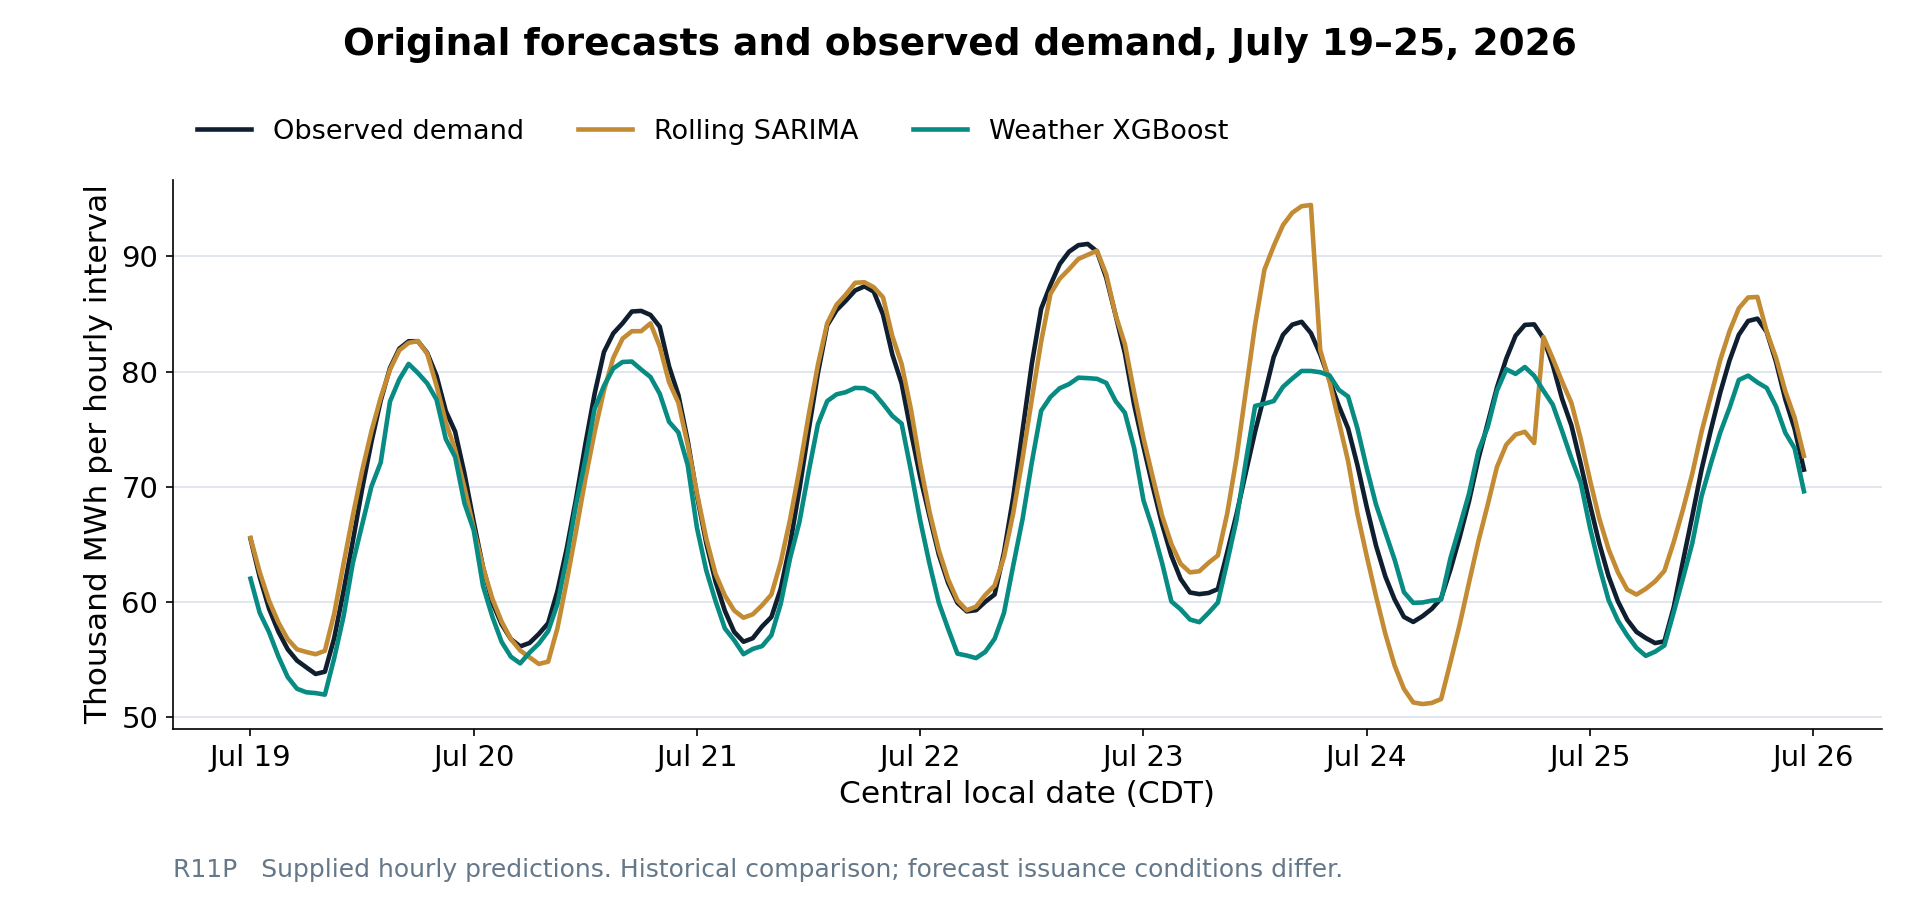

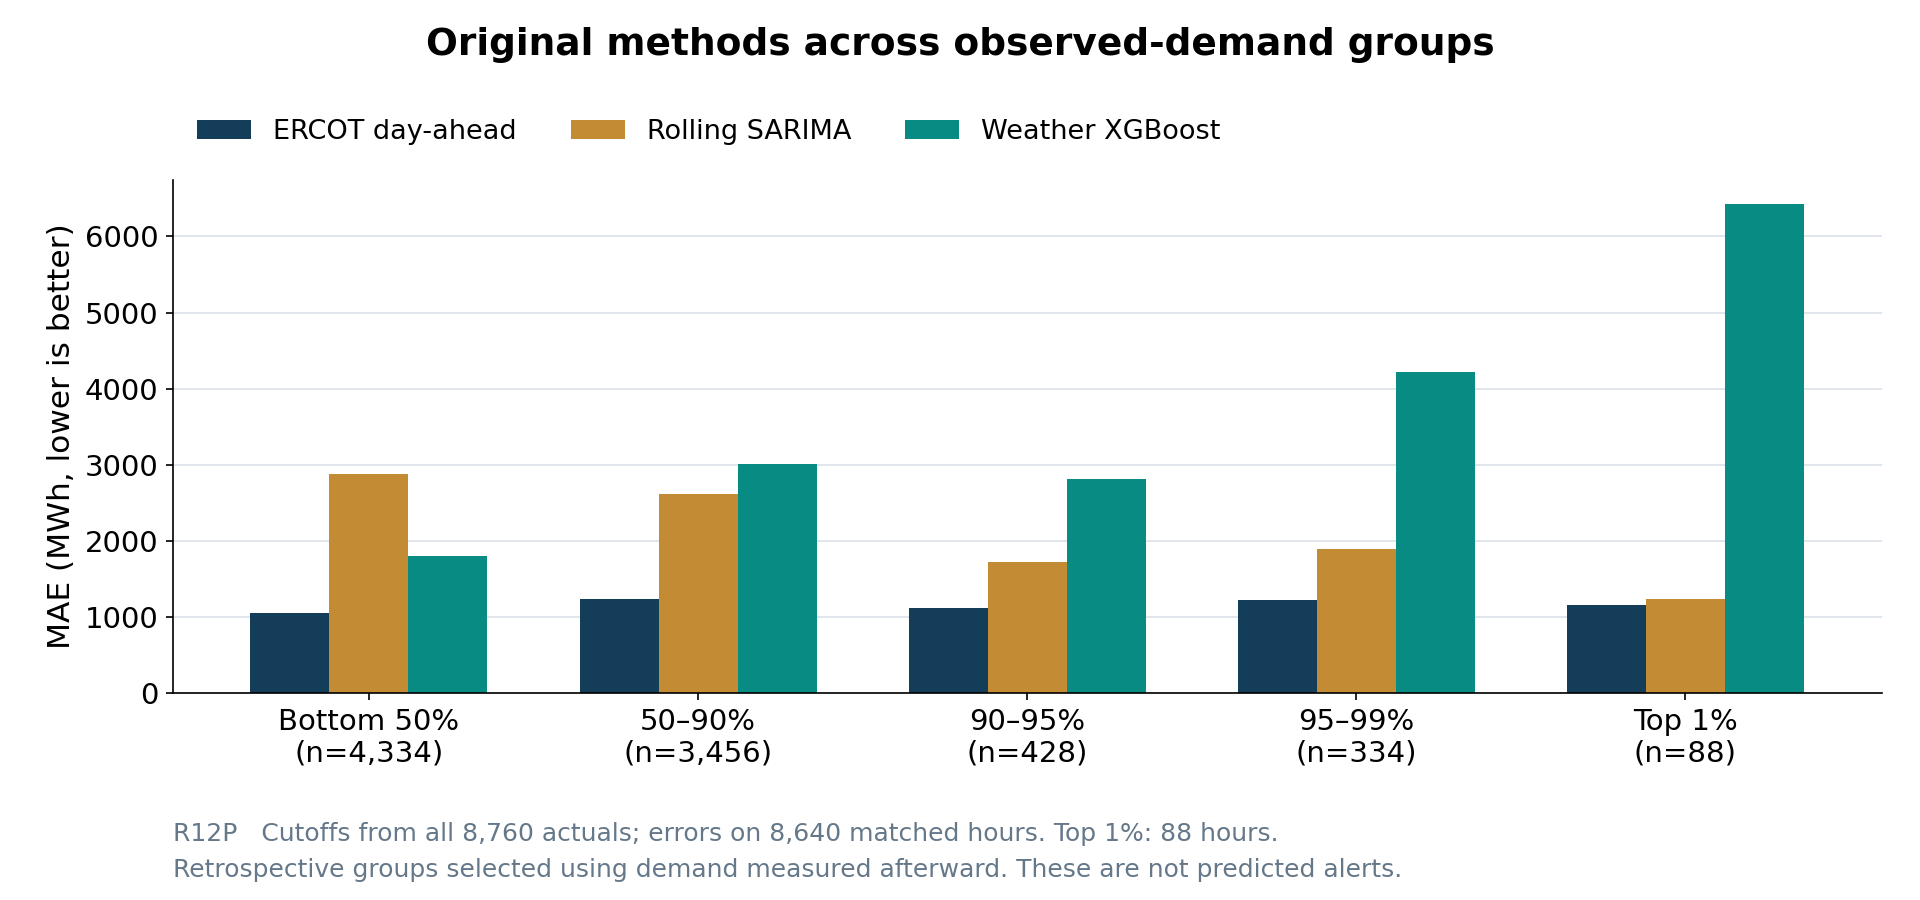

In [2]:
rows=research.empirical(state)
research.qa_assets(rows)
from IPython.display import Image,display
for row in rows:
    display(Image(filename=str(ROOT/row['path'])))

**Interpretation boundary:** Historical observed weather is not advance weather information. Forecast issue times/horizons differ. High-demand groups are identified retrospectively. No dispatch cost, reserve or outage outcome was measured. The missing failed static SARIMA series is not reconstructed.